# Interpretasi model final dengan SHAP

Notebook ini menjelaskan model final tanpa mengubah konfigurasi
atau melakukan evaluasi test ulang.

Background terdiri dari 100 development observations.
Penjelasan diperiksa pada 128 development observations lain.

TreeSHAP dihitung dalam probability space untuk setiap anggota.
Kontribusi seluruh kolom OHE dari fitur yang sama dijumlahkan,
kemudian kontribusi anggota digabung dengan bobot 75/25.

Fitur turunan dipertahankan sebagai variabel tersendiri.
Hasilnya merupakan penjelasan input model yang dikelompokkan,
bukan pengukuran kausal atau Shapley value langsung atas
23 fitur mentah dengan semua dependensinya.

Base probability + seluruh kontribusi harus merekonstruksi
probabilitas default ensemble dalam toleransi numerik.

In [1]:
import importlib
import json
import subprocess
import sys

from src import config

importlib.reload(config)

metadata = json.loads(
    config.FINAL_METADATA_PATH.read_text(encoding="utf-8")
)

config.INFERENCE_CONSTRAINTS_PATH.write_text(
    "\n".join(
        f"{package}=={package_version}"
        for package, package_version in metadata["versions"].items()
    ) + "\n",
    encoding="utf-8",
)

subprocess.run(
    [
        sys.executable,
        "-m", "pip", "install",
        "-c", str(config.INFERENCE_CONSTRAINTS_PATH),
        "shap[plots]==0.51.0",
        "numba==0.64.0",
        "fastapi",
        "pydantic>=2,<3",
        "uvicorn[standard]",
        "httpx",
        "pytest",
    ],
    check=True,
)


CompletedProcess(args=['d:\\proj-1\\.venv\\Scripts\\python.exe', '-m', 'pip', 'install', '-c', 'D:\\proj-1\\models\\blend_refinement_xgb75_v09\\runtime-constraints.txt', 'shap[plots]==0.51.0', 'numba==0.64.0', 'fastapi', 'pydantic>=2,<3', 'uvicorn[standard]', 'httpx', 'pytest'], returncode=0)

In [2]:
import json
from datetime import datetime, timezone
from importlib.metadata import version

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
from IPython.display import display

from src import config
from src.data_loader import load_and_split
from src.explain import (
    CreditExplainer,
    file_sha256,
    load_final_bundle,
    reason_table,
)

bundle, model_metadata = load_final_bundle()

assert model_metadata["dataset_sha256"] == file_sha256(
    config.DATA_PATH
)

split = load_and_split()

background = split.X_train.sample(
    n=config.SHAP_BACKGROUND_SIZE,
    random_state=config.RANDOM_STATE,
)

explanation_sample = split.X_train.drop(
    index=background.index
).sample(
    n=config.SHAP_SAMPLE_SIZE,
    random_state=config.RANDOM_STATE,
)

background.to_csv(config.SHAP_BACKGROUND_PATH, index=False)

# Baca kembali file yang nanti digunakan API.
background = pd.read_csv(config.SHAP_BACKGROUND_PATH)

preprocessor = bundle["model"].named_estimators_[
    "xgb"
].named_steps["preprocess"]

categorical_columns = next(
    list(columns)
    for name, _, columns in preprocessor.transformers_
    if name == "categorical"
)
encoder = preprocessor.named_transformers_["categorical"]

categorical_codes = {
    column: [int(value) for value in categories]
    for column, categories in zip(
        categorical_columns,
        encoder.categories_,
        strict=True,
    )
}

sample_row = background.iloc[0]
example_request = {
    column: (
        int(sample_row[column])
        if column in config.CATEGORICAL_COLUMNS or column == "AGE"
        else float(sample_row[column])
    )
    for column in config.FEATURE_COLUMNS
}

schema_document = {
    "model_sha256": model_metadata["model_sha256"],
    "categorical_codes": categorical_codes,
    "example_request": example_request,
}

config.FINAL_SCHEMA_PATH.write_text(
    json.dumps(schema_document, indent=2, allow_nan=False),
    encoding="utf-8",
)

display(pd.DataFrame([
    {"package": package, "version": version(package)}
    for package in (
        "shap", "numba", "numpy", "pandas",
        "scikit-learn", "xgboost", "lightgbm",
        "fastapi", "pydantic",
    )
]))

print("Background rows:", len(background))
print("Explanation rows:", len(explanation_sample))

d:\proj-1\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,package,version
0,shap,0.51.0
1,numba,0.64.0
2,numpy,2.4.6
3,pandas,3.0.6
4,scikit-learn,1.9.1
5,xgboost,3.2.0
6,lightgbm,4.7.0
7,fastapi,0.142.2
8,pydantic,2.13.5


Background rows: 100
Explanation rows: 128


In [3]:
explainer = CreditExplainer(
    model=bundle["model"],
    background=background,
)

explanation_result = explainer.explain(explanation_sample)

print("TABEL 1 — Pemeriksaan rekonstruksi probabilitas")
display(explanation_result.checks)

global_importance = (
    explanation_result.contributions.abs()
    .mean()
    .mul(100)
    .rename("mean_absolute_contribution_pp")
    .sort_values(ascending=False)
    .reset_index()
    .rename(columns={"index": "feature"})
)

print("TABEL 2 — Kontribusi rata-rata pada sampel development")
display(global_importance.head(10).round(4))

# Contoh lokal: skor tertinggi dari sampel yang telah dijelaskan.
local_position = int(
    np.argmax(explanation_result.probabilities)
)
local_reasons = reason_table(
    explanation_result,
    row_position=local_position,
)

local_probability = float(
    explanation_result.probabilities[local_position]
)

print("TABEL 3 — Penjelasan satu observasi")
display(local_reasons.head(10).round(4))

print(
    "Base probability:",
    round(explanation_result.base_probability, 6),
)
print("Probability default:", round(local_probability, 6))
print("Threshold:", round(float(bundle["threshold"]), 6))
print("High-risk:", local_probability >= bundle["threshold"])

config.SHAP_REPORTS_DIR.mkdir(parents=True, exist_ok=True)

explanation_result.checks.to_csv(
    config.SHAP_REPORTS_DIR / "additivity_checks.csv",
    index=False,
)
global_importance.to_csv(
    config.SHAP_REPORTS_DIR / "global_importance.csv",
    index=False,
)
local_reasons.to_csv(
    config.SHAP_REPORTS_DIR / "local_explanation.csv",
    index=False,
)

explanation_metadata = {
    "created_at": datetime.now(timezone.utc).isoformat(),
    "model_sha256": model_metadata["model_sha256"],
    "background_sha256": file_sha256(config.SHAP_BACKGROUND_PATH),
    "schema_sha256": file_sha256(config.FINAL_SCHEMA_PATH),
    "background_rows": len(background),
    "background_scope": "development_only",
    "explanation_sample_rows": len(explanation_sample),
    "sample_source_indices": explanation_sample.index.tolist(),
    "method": "interventional_tree_shap",
    "output_space": "probability",
    "aggregation": "sum_ohe_then_weight_members",
    "additivity_atol": config.SHAP_ADDITIVITY_ATOL,
    "versions": {
        package: version(package)
        for package in ("shap", "numba")
    },
}

config.SHAP_METADATA_PATH.write_text(
    json.dumps(explanation_metadata, indent=2, allow_nan=False),
    encoding="utf-8",
)

print("SHAP terverifikasi dan laporan tersimpan.")

TABEL 1 — Pemeriksaan rekonstruksi probabilitas


,model,max_absolute_error
0,xgb,4.287016e-07
1,lgbm,2.777430e-08
2,weighted_blend,3.229229e-07


TABEL 2 — Kontribusi rata-rata pada sampel development


,feature,mean_absolute_contribution_pp
0,PAY_0,4.8711
1,bill_latest_to_limit,2.2557
2,PAY_AMT2,1.7802
3,BILL_AMT1,1.7032
4,PAY_2,1.6360
5,PAY_AMT3,1.5927
6,PAY_AMT1,1.5854
7,LIMIT_BAL,1.5734
8,bill_std,1.4480
9,BILL_AMT3,1.3016


TABEL 3 — Penjelasan satu observasi


,feature,value,value_label,contribution_pp,definition
0,PAY_0,3.0,Keterlambatan 3 bulan,20.3615,PAY_0
1,PAY_2,2.0,Keterlambatan 2 bulan,9.3864,PAY_2
2,bill_std,0.0,0,7.3237,Population standard deviation of BILL_AMT1-BIL...
3,PAY_3,2.0,Keterlambatan 2 bulan,6.9592,PAY_3
4,PAY_AMT3,0.0,0,5.1598,PAY_AMT3
5,PAY_AMT1,0.0,0,3.2890,PAY_AMT1
6,payment_mean,0.0,0,3.2226,Mean of PAY_AMT1-PAY_AMT6
7,PAY_AMT2,0.0,0,3.1783,PAY_AMT2
8,BILL_AMT1,2443.0,2443,3.0312,BILL_AMT1
9,BILL_AMT3,2443.0,2443,2.2316,BILL_AMT3


Base probability: 0.21068
Probability default: 0.872774
Threshold: 0.158931
High-risk: True
SHAP terverifikasi dan laporan tersimpan.


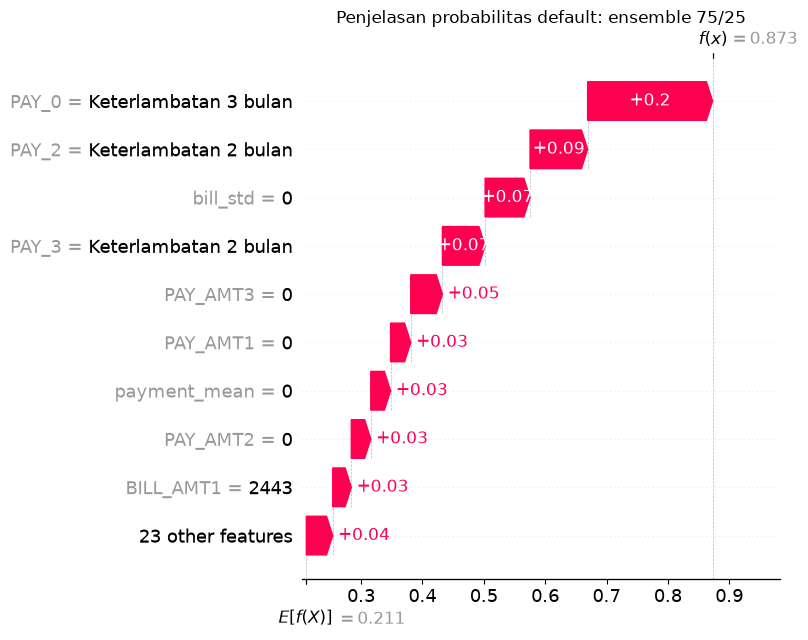

In [4]:
feature_labels = {
    row["feature"]: f'{row["feature"]} = {row["value_label"]}'
    for row in local_reasons.to_dict(orient="records")
}

waterfall_explanation = shap.Explanation(
    values=explanation_result.contributions.iloc[
        local_position
    ].to_numpy(),
    base_values=explanation_result.base_probability,
    feature_names=[
        feature_labels[feature]
        for feature in explanation_result.contributions.columns
    ],
)

shap.plots.waterfall(
    waterfall_explanation,
    max_display=10,
    show=False,
)
plt.title("Penjelasan probabilitas default: ensemble 75/25")
plt.tight_layout()
plt.savefig(
    config.SHAP_REPORTS_DIR / "local_waterfall.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

### Interpretasi hasil SHAP

Rekonstruksi SHAP ensemble memiliki selisih maksimum sekitar
3,23 × 10⁻⁷ terhadap probabilitas model, di bawah toleransi 10⁻⁵.

Pada 128 observasi development yang diperiksa, PAY_0 memiliki
rata-rata kontribusi absolut terbesar, sebesar 4,87 percentage
points. Nilai absolut menunjukkan besar kontribusi, bukan arah.

Pada contoh lokal, base probability 21,07% meningkat menjadi
87,28% setelah seluruh kontribusi dijumlahkan. Kontributor
positif terbesar adalah PAY_0=3 (+20,36 percentage points)
dan PAY_2=2 (+9,39 percentage points).

Skor melampaui threshold 15,89% sehingga observasi ditandai
high-risk. SHAP menjelaskan prediksi model relatif terhadap
background; hasilnya bukan bukti kausal atau kepastian default.